**Part I. Set-Up**

First, we need to make sure we are working with a version of Tensorflow that complements our capabilities on our embedded system.

The Pi runs Python 3.7. We will upgrade to use a tflite_runtime interpreter == 2.11.0 BUT we will still have to downgrade tensorflow (for model development) to 2.12.0 so that the oeprations are compatible for inference on our embedded system.

In [2]:
!pip uninstall tensorflow
!pip install tensorflow==2.12.0

Found existing installation: tensorflow 2.18.0
Uninstalling tensorflow-2.18.0:
  Would remove:
    /usr/local/bin/import_pb_to_tensorboard
    /usr/local/bin/saved_model_cli
    /usr/local/bin/tensorboard
    /usr/local/bin/tf_upgrade_v2
    /usr/local/bin/tflite_convert
    /usr/local/bin/toco
    /usr/local/bin/toco_from_protos
    /usr/local/lib/python3.11/dist-packages/tensorflow-2.18.0.dist-info/*
    /usr/local/lib/python3.11/dist-packages/tensorflow/*
Proceed (Y/n)? Y
Y
  Successfully uninstalled tensorflow-2.18.0
INFO: pip is looking at multiple versions of jax to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of jax to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 586.0/586.0 MB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 65.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [1]:
#Make sure it is 2.12.0 before doing any work
import tensorflow as tf
print(tf.__version__)

2.12.0


Next we need to mount our Drive and map to where our data lives. Please make sure that the CSV files given in the github repository are saved in a folder of your choosing on your Google Drive. Then map to that directory. Feel free to use

```
!ls
```

 to check that your files are there!

In [2]:
# prompt: navigate to a folder in my google drive My Drive > data > fall_data

import os
from google.colab import drive

drive.mount('/content/drive')
%cd /content/drive/MyDrive/HumanData
!pwd


Mounted at /content/drive
/content/drive/MyDrive/HumanData
/content/drive/MyDrive/HumanData


In [3]:
!ls

EMB_Model_MH_BA_optimized.tflite       nn_model_window_10np_Opt_test.tflite
EMB_Model_MH_BA_opt.tflite	       nn_window_model_raw.tflite
EMB_Model_MH_BA.tflite		       rf_model.pkl
fall_detect_v1.ipynb		       sitting_data.csv
falling_data.csv		       standing_data.csv
nn_model_raw_1np_Micaela_Helou.tflite  walking_data.csv
nn_model_raw.tflite


**Part II. Data Exploration**

Now let's pull in the data using


```
pd.read_csv()
```
Label the columns and explore this data set.


*   How many data points are there in each?
*   Maybe find a way to plot a couple of the parameters over time to see what the "behavior" looks like?




In [4]:
import pandas as pd

# Load the four CSV files into dataframes without the index
df_sitting = pd.read_csv('sitting_data.csv', index_col=False)
df_standing = pd.read_csv('standing_data.csv', index_col=False)
df_walking = pd.read_csv('walking_data.csv', index_col=False)
df_falling = pd.read_csv('falling_data.csv', index_col=False)

# Specify the columns that contain gyro and accel data
gyro_accel_columns = ['Gyro_X', 'Gyro_Y', 'Gyro_Z', 'Accel_X', 'Accel_Y', 'Accel_Z']  # Replace with actual column names



In [5]:
df_sitting.drop("Index", axis=1).describe()

,Gyro_X,Gyro_Y,Gyro_Z,Accel_X,Accel_Y,Accel_Z,Label
count,2800.000000,2800.000000,2800.000000,2800.000000,2800.000000,2800.000000,2800.0
mean,0.000745,0.002211,-0.005333,0.041702,0.023824,0.965907,0.0
std,0.206001,0.189151,0.252217,0.111911,0.132400,0.057110,0.0
min,-3.571771,-1.906741,-2.969609,-1.785609,-0.987096,0.139638,0.0
25%,-0.011232,-0.012002,-0.007701,0.012001,-0.024424,0.950661,0.0
50%,0.001364,0.000354,0.001768,0.082674,0.025736,0.964674,0.0
75%,0.012809,0.012252,0.012401,0.098918,0.070956,0.982586,0.0
max,2.852820,1.743551,2.169600,0.633026,0.726678,1.645929,0.0


In [6]:
df_standing.drop("Index", axis=1).describe()

,Gyro_X,Gyro_Y,Gyro_Z,Accel_X,Accel_Y,Accel_Z,Label
count,2800.000000,2800.000000,2800.000000,2800.000000,2800.000000,2800.000000,2800.0
mean,0.004377,-0.001945,-0.008968,0.004213,0.122998,0.910049,1.0
std,0.169145,0.152011,0.196855,0.114433,0.256565,0.209666,0.0
min,-1.862282,-1.147398,-2.158294,-0.559823,-0.288989,-0.059052,1.0
25%,-0.019076,-0.018568,-0.024052,-0.084541,-0.007719,0.938964,1.0
50%,0.002277,0.000888,0.002001,0.051883,0.049651,0.960653,1.0
75%,0.022837,0.019618,0.026691,0.084674,0.089833,0.979905,1.0
max,2.177781,1.446113,1.258275,0.474467,1.110776,1.544794,1.0


In [7]:
df_walking.drop("Index", axis=1).describe()

,Gyro_X,Gyro_Y,Gyro_Z,Accel_X,Accel_Y,Accel_Z,Label
count,2800.000000,2800.000000,2800.000000,2800.000000,2800.000000,2800.000000,2800.0
mean,-0.022385,-0.004684,-0.151202,0.055319,0.060286,0.944781,2.0
std,0.279084,0.307917,0.803596,0.144050,0.193507,0.132298,0.0
min,-3.920907,-1.778459,-3.031022,-0.553406,-0.384997,0.042891,2.0
25%,-0.144172,-0.127780,-0.676674,-0.031842,-0.053552,0.906735,2.0
50%,-0.013351,0.001871,-0.191228,0.067400,0.043703,0.951636,2.0
75%,0.109768,0.131794,0.308151,0.149104,0.131897,0.998487,2.0
max,2.040528,5.151937,3.130269,0.640057,1.138212,1.564290,2.0


In [8]:
df_falling.drop("Index", axis=1).describe()

,Gyro_X,Gyro_Y,Gyro_Z,Accel_X,Accel_Y,Accel_Z,Label
count,2800.000000,2800.000000,2800.000000,2800.000000,2800.000000,2800.000000,2800.0
mean,0.040098,-0.018909,0.019843,0.106974,0.037615,0.907081,3.0
std,1.024962,1.196989,0.933477,0.365618,0.371159,0.503906,0.0
min,-8.631013,-10.086443,-4.828369,-8.087323,-7.903525,-1.545957,3.0
25%,-0.257121,-0.391505,-0.309383,-0.014070,-0.092631,0.703492,3.0
50%,0.054276,-0.026904,0.025655,0.105464,0.036176,0.923367,3.0
75%,0.421793,0.322486,0.391023,0.256629,0.175600,1.089812,3.0
max,9.962255,10.025426,9.727967,4.248622,3.945137,5.210726,3.0


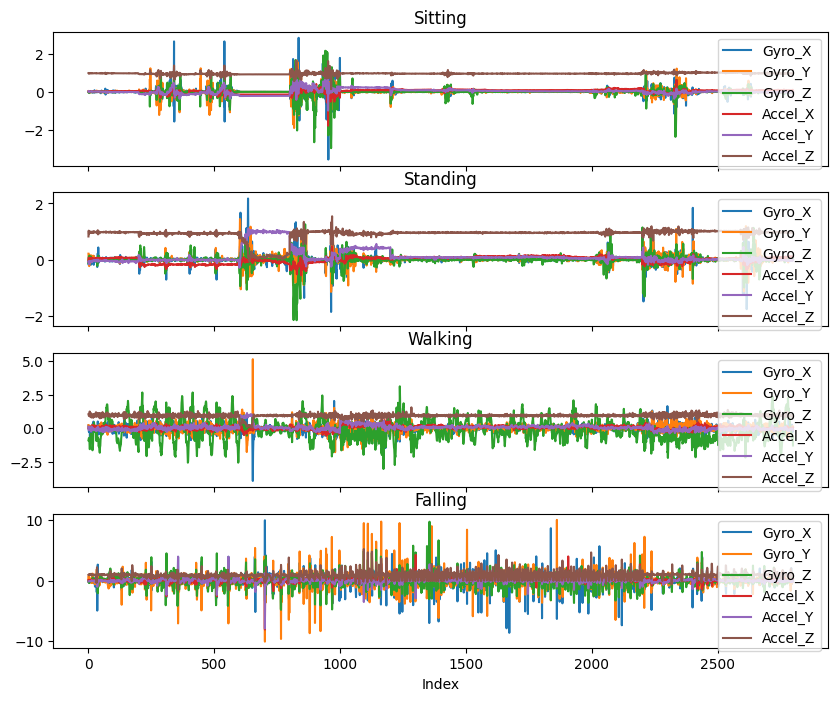

In [9]:
import matplotlib.pyplot as plt
import numpy as np

fig, axs = plt.subplots(4, 1, figsize=(10, 8), sharex=True)

axs[0].plot(df_sitting.index, df_sitting[['Gyro_X', 'Gyro_Y', 'Gyro_Z', 'Accel_X', 'Accel_Y', 'Accel_Z']])
axs[0].set_title('Sitting')
axs[0].legend(['Gyro_X', 'Gyro_Y', 'Gyro_Z', 'Accel_X', 'Accel_Y', 'Accel_Z'])

axs[1].plot(df_standing.index, df_standing[['Gyro_X', 'Gyro_Y', 'Gyro_Z', 'Accel_X', 'Accel_Y', 'Accel_Z']])
axs[1].set_title('Standing')
axs[1].legend(['Gyro_X', 'Gyro_Y', 'Gyro_Z', 'Accel_X', 'Accel_Y', 'Accel_Z'])

axs[2].plot(df_walking.index, df_walking[['Gyro_X', 'Gyro_Y', 'Gyro_Z', 'Accel_X', 'Accel_Y', 'Accel_Z']])
axs[2].set_title('Walking')
axs[2].legend(['Gyro_X', 'Gyro_Y', 'Gyro_Z', 'Accel_X', 'Accel_Y', 'Accel_Z'])

axs[3].plot(df_falling.index, df_falling[['Gyro_X', 'Gyro_Y', 'Gyro_Z', 'Accel_X', 'Accel_Y', 'Accel_Z']])
axs[3].set_title('Falling')
axs[3].legend(['Gyro_X', 'Gyro_Y', 'Gyro_Z', 'Accel_X', 'Accel_Y', 'Accel_Z'])

plt.xlabel('Index')
plt.show()

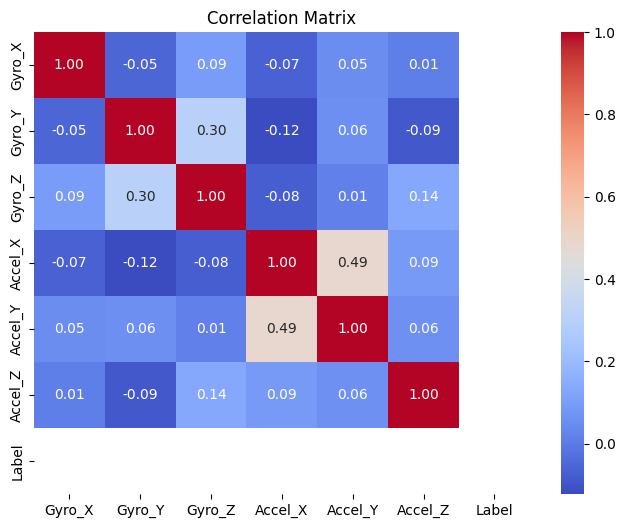

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(df_sitting.drop("Index", axis=1).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

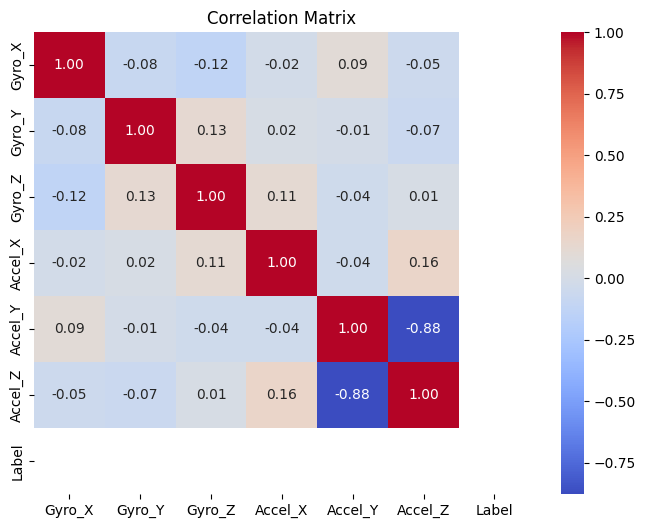

In [11]:
plt.figure(figsize=(8, 6))
sns.heatmap(df_standing.drop("Index", axis=1).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

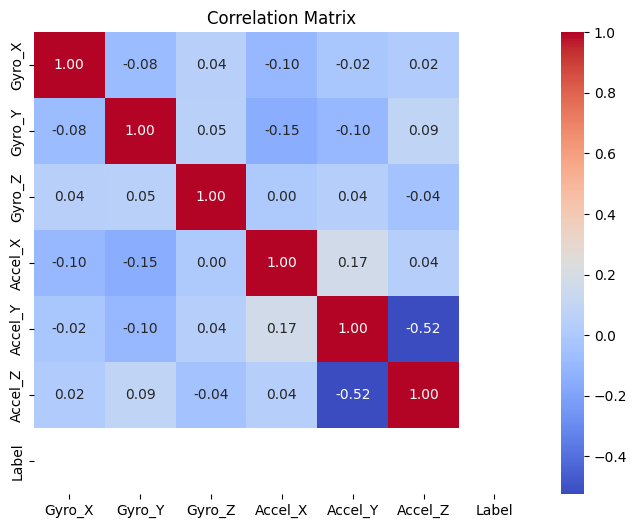

In [12]:
plt.figure(figsize=(8, 6))
sns.heatmap(df_walking.drop("Index", axis=1).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

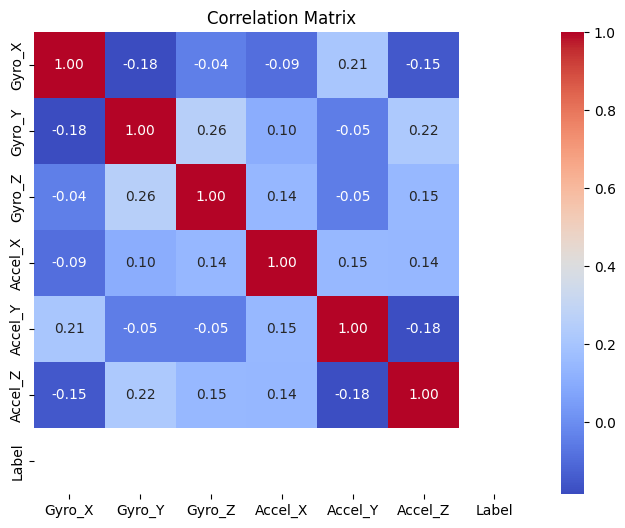

In [13]:
plt.figure(figsize=(8, 6))
sns.heatmap(df_falling.drop("Index", axis=1).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

#####**Part III - Tensorflow**

In [10]:
# Importing libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout,Conv1D, MaxPooling1D, Flatten, Dense
from tensorflow.keras.utils import to_categorical
from sklearn import svm
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier

#####**Part IV - A More Sophisticated NN**

In [11]:
# Function to create a sliding window dataframe for specific columns
def create_sliding_window_df(df, columns, window_size):
    sliding_window_data = []
    for i in range(len(df) - window_size + 1):
        window = df[columns].iloc[i:i + window_size].values.flatten()
        sliding_window_data.append(window)
    return pd.DataFrame(sliding_window_data)

In [12]:
# Define your window_size
window_size = 10

# Create new dataframes with sliding windows for gyro and accel data
df_sitting_windowed = create_sliding_window_df(df_sitting, gyro_accel_columns,window_size)
df_standing_windowed = create_sliding_window_df(df_standing, gyro_accel_columns,window_size)
df_walking_windowed = create_sliding_window_df(df_walking, gyro_accel_columns,window_size)
df_falling_windowed = create_sliding_window_df(df_falling, gyro_accel_columns,window_size)

# Add labels to the windowed dataframes
df_sitting_windowed['Label'] = 0
df_standing_windowed['Label'] = 1
df_walking_windowed['Label'] = 2
df_falling_windowed['Label'] = 3

In [13]:
# Concatenate all windowed dataframes into one large dataframe X
X_df = pd.concat([df_sitting_windowed, df_standing_windowed, df_walking_windowed, df_falling_windowed], ignore_index=True)

# Randomize the order of the X data
X_df = shuffle(X_df, random_state=42)
# Separate the labels into a dataframe y
y_df = X_df.pop('Label')

label_encoder = LabelEncoder()
y_encoded_df = label_encoder.fit_transform(y_df)
y_categorical_df = to_categorical(y_encoded_df, num_classes=4)  # Ensure 4 classes for one-hot encoding

In [14]:
n_features = 6
X_array = X_df.values # convert the X_df to a numpy array
X_reshape = X_array.reshape((X_array.shape[0], window_size, n_features))

# Split the data into training, testing, and validation sets
X_train, X_temp, y_train, y_temp = train_test_split(X_reshape, y_categorical_df, test_size=0.4, random_state=42) #use y_categorical_df
X_test, X_val, y_test, y_val = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

print("Data has been successfully split into training, testing, and validation sets.")
print(f"Training set size: {len(X_train)}")
print(f"Testing set size: {len(X_test)}")
print(f"Validation set size: {len(X_val)}")

Data has been successfully split into training, testing, and validation sets.
Training set size: 6698
Testing set size: 2233
Validation set size: 2233


In [15]:
# Build the CNN model
model = Sequential()
model.add(Conv1D(64, 3, activation='relu', input_shape=(window_size, n_features)))
model.add(MaxPooling1D(2))
model.add(Conv1D(128, 3, activation='relu'))
model.add(MaxPooling1D(2))
model.add(Flatten())
model.add(Dense(100, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(4, activation='softmax')) # Assuming 4 classes: sitting, standing, walking, falling

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model
history = model.fit(X_train, y_train, epochs=100, batch_size=32, validation_data=(X_val, y_val))

# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test)
print(f'Test Accuracy: {accuracy:.2f}')

Epoch 1/100
210/210 [==============================] - 7s 14ms/step - loss: 0.8788 - accuracy: 0.6017 - val_loss: 0.6695 - val_accuracy: 0.7210
Epoch 2/100
210/210 [==============================] - 2s 9ms/step - loss: 0.6345 - accuracy: 0.7080 - val_loss: 0.5809 - val_accuracy: 0.7394
Epoch 3/100
210/210 [==============================] - 1s 7ms/step - loss: 0.5709 - accuracy: 0.7402 - val_loss: 0.5523 - val_accuracy: 0.7474
Epoch 4/100
210/210 [==============================] - 1s 4ms/step - loss: 0.5239 - accuracy: 0.7596 - val_loss: 0.5317 - val_accuracy: 0.7528
Epoch 5/100
210/210 [==============================] - 1s 3ms/step - loss: 0.4883 - accuracy: 0.7793 - val_loss: 0.5462 - val_accuracy: 0.7864
Epoch 6/100
210/210 [==============================] - 1s 3ms/step - loss: 0.4562 - accuracy: 0.7922 - val_loss: 0.4609 - val_accuracy: 0.8191
Epoch 7/100
210/210 [==============================] - 1s 4ms/step - loss: 0.4223 - accuracy: 0.8117 - val_loss: 0.4331 - val_accuracy: 0.817

In [16]:
X_reshape.shape

(11164, 10, 6)

In [17]:
X_train.shape

(6698, 10, 6)

#####**Part V - Optimize and Save your Model**

In [18]:
!pip install tensorflow-model-optimization

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 242.5/242.5 kB 15.9 MB/s eta 0:00:00


In [19]:
import tensorflow_model_optimization.sparsity.keras as sp_keras
from tensorflow_model_optimization.sparsity.keras import UpdatePruningStep

In [20]:
pruning_params = {'pruning_schedule': sp_keras.PolynomialDecay(initial_sparsity = 0.10, final_sparsity = 0.80, begin_step = 2000, end_step = 4000)}

model_for_pruning = sp_keras.prune_low_magnitude(model, **pruning_params)

# Compile the pruned model
model_for_pruning.compile(optimizer='adam', loss='categorical_crossentropy', metrics = ['accuracy'])

# Train the pruned model
pruning_history = model_for_pruning.fit(X_train, y_train, epochs = 100, callbacks = [UpdatePruningStep()])

# Evaluate the pruned model
pruned_loss, pruned_accuracy = model_for_pruning.evaluate(X_test, y_test)
print(f'Test Accuracy: {pruned_accuracy:.2f}')

Epoch 1/100
210/210 [==============================] - 6s 6ms/step - loss: 0.0300 - accuracy: 0.9901
Epoch 2/100
210/210 [==============================] - 1s 5ms/step - loss: 0.0456 - accuracy: 0.9840
Epoch 3/100
210/210 [==============================] - 1s 3ms/step - loss: 0.0222 - accuracy: 0.9921
Epoch 4/100
210/210 [==============================] - 1s 3ms/step - loss: 0.0481 - accuracy: 0.9888
Epoch 5/100
210/210 [==============================] - 1s 3ms/step - loss: 0.0330 - accuracy: 0.9897
Epoch 6/100
210/210 [==============================] - 1s 3ms/step - loss: 0.0319 - accuracy: 0.9885
Epoch 7/100
210/210 [==============================] - 1s 3ms/step - loss: 0.0211 - accuracy: 0.9927
Epoch 8/100
210/210 [==============================] - 1s 3ms/step - loss: 0.0246 - accuracy: 0.9910
Epoch 9/100
210/210 [==============================] - 1s 3ms/step - loss: 0.0348 - accuracy: 0.9891
Epoch 10/100
210/210 [==============================] - 1s 3ms/step - loss: 0.0466 - accura

In [22]:
#Set-up
model = model
model_file_name = 'EMB_Model_MH_BA_OPTIMIZED.tflite' #change the name for your model

# Convert the model to TensorFlow Lite format
converter = tf.lite.TFLiteConverter.from_keras_model(model)

converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS,  # Built-in operations - ReLU, Conv2D, MaxPool, Dense, etc...
    tf.lite.OpsSet.SELECT_TF_OPS     # Select TensorFlow operations - maybe for LSTM/RNN layers
]
converter.optimizations = [tf.lite.Optimize.DEFAULT] # See below
converter.inference_input_type = tf.float32
converter.inference_output_type = tf.float32
tflite_model = converter.convert()

# Save the TensorFlow Lite model to a file
with open(model_file_name, 'wb') as f:
    f.write(tflite_model)

print("Model converted to TensorFlow Lite and saved as ", model_file_name)

Model converted to TensorFlow Lite and saved as  EMB_Model_MH_BA_OPTIMIZED.tflite


####**Part VI - Evaluate TFLite Model**

In [ ]:
# Load the TFLite model
interpreter = tf.lite.Interpreter(model_path="EMB_Model_MH_BA_optimized.tflite")
interpreter.allocate_tensors()

# Get input and output tensors
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

input_details = interpreter.get_input_details()
input_shape = input_details[0]['shape']

y_pred = []

for i in range(X_test.shape[0]):  # Iterate through each sample
    input_data = X_test[i:i+1]  # Get a single sample
    interpreter.set_tensor(input_details[0]['index'], input_data.astype(np.float32))
    interpreter.invoke()
    output_data = interpreter.get_tensor(output_details[0]['index'])

    predicted_class = np.argmax(output_data[0])  # Max probability
    y_pred.append(predicted_class)


# Convert y_test to a 1D array of class labels because it is one-hot encoded.
y_true = np.argmax(y_test, axis=1)

# Calculate accuracy
accuracy = accuracy_score(y_true, y_pred)
print(f"Accuracy: {accuracy}")